In [ ]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import string

In [ ]:
# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
import pandas as pd
# Load dataset
df = pd.read_csv("emotion_sentimen_dataset.csv")
print(df.head())

   Unnamed: 0                                               text  Emotion
0           0  i seriously hate one subject to death but now ...     hate
1           1                 im so full of life i feel appalled  neutral
2           2  i sit here to write i start to dig out my feel...  neutral
3           3  ive been really angry with r and i feel like a...    anger
4           4  i feel suspicious if there is no one outside l...  neutral


In [ ]:
df

,Unnamed: 0,text,Emotion
0,0,i seriously hate one subject to death but now ...,hate
1,1,im so full of life i feel appalled,neutral
2,2,i sit here to write i start to dig out my feel...,neutral
3,3,ive been really angry with r and i feel like a...,anger
4,4,i feel suspicious if there is no one outside l...,neutral
...,...,...,...
56245,56245,i feel like i m being punished for taking my time,neutral
56246,56246,i looked up i could feel the sun on my face an...,neutral
56247,56247,im so excited scared nervous ecstatic its hard...,enthusiasm
56248,56248,i have gone through my life feeling a bit inad...,neutral


In [ ]:
# Lowercasing
df.loc[:, 'text'] = df['text'].astype(str).apply(lambda x: x.lower())

In [ ]:
# Tokenization
df.loc[:, 'text'] = df['text'].apply(word_tokenize)

In [ ]:
#removing punctuation
df.loc[:,'text']=df['text'].apply(lambda x: [word for word in x if word not in string.punctuation])

In [ ]:
#removing stopwords
stop_words=set(stopwords.words('english'))
df.loc[:,'text']=df['text'].apply(lambda x:[word for word in x if word not in stop_words])

In [ ]:
!pip install gensim

In [ ]:
#stemming
stemmer=PorterStemmer()
df.loc[:,'text']=df['text'].apply(lambda x:[stemmer.stem(word) for word in x])

In [ ]:
#vectorization and embedding generation
import os
from gensim.models import KeyedVectors
import gensim.downloader as api

#define the path to save the word2vec model
model_path="word2vec_model.bin"

#check if the word2vec model file exits locally
if not os.path.exists(model_path):
  #download the pre-trained word2vec model if it doesn't exit
  try:
    word2vec_model=api.load("word2vec-google-news-300")
  except urllib.error.ContentTooShortError:
    print("Download intrerrputed. Retrying...")
    word2vec_model=api.load("word2vec-google-news-300")
  #Save the model to the specified path
  word2vec_model.save_word2vec_format(model_path,binary=True)
else:


  #load the word2vec model from the local file
  word2vec_model=KeyedVectors.load_word2vec_format(model_path,binary=True)

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [ ]:
#Define a function to vectorize text using the loaded word2vec model
def vectorize_text(text):
    vectorized_text = []  # create a list to store word vectors
    for word in text:
        if word in word2vec_model:
            vectorized_text.append(word2vec_model[word])
    return vectorized_text


In [ ]:
#Apply word2vec vectorization to the preprocessed text data
X_word2vec = df['text'].apply(vectorize_text)

# print shape
print("Shape of the word2vec matrix:", len(X_word2vec), len(X_word2vec[0]))


Shape of the word2vec matrix: 56250 7


In [ ]:
X_word2vec

,text
0,"[[0.025878906, 0.07324219, 0.032714844, 0.0815..."
1,"[[-0.036621094, 0.014526367, 0.03515625, 0.230..."
2,"[[0.06933594, -0.052490234, 0.16308594, 0.3476..."
3,"[[-0.41210938, 0.18847656, -0.234375, 0.296875..."
4,"[[-0.055664062, 0.01373291, -0.14160156, -0.05..."
...,...
56245,"[[-0.055664062, 0.01373291, -0.14160156, -0.05..."
56246,"[[-0.17089844, 0.1796875, 0.022949219, 0.07421..."
56247,"[[-0.036621094, 0.014526367, 0.03515625, 0.230..."
56248,"[[-0.026489258, 0.32226562, -0.125, 0.02600097..."


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import numpy as np

#step2:Generate word embeddings
word_embeddings=[]
for text in df['text']:
  #tokenize text and get word2vec embeddings for each word
  embeddings=[word2vec_model[word] for word in text if word in word2vec_model]
  #aggregate word embeddings (e.g.,by averaging)
  if embeddings:
    text_embedding=np.mean(embeddings,axis=0)
    word_embeddings.append(text_embedding)
  else:
    #if no embeddings found any word,use zero vector
    word_embeddings.append(np.zeros(word2vec_model.vector_size ))

In [ ]:
word_embeddings

[array([ 0.01824079, -0.0110648 ,  0.12172154,  0.08890206, -0.09940011,
         0.04309954,  0.11579241, -0.05934361,  0.21944754,  0.16381836,
        -0.00233677, -0.1045881 , -0.06540353,  0.05859375,  0.00344413,
         0.03537423,  0.01821028,  0.08489119, -0.01974051, -0.01640538,
        -0.02296666, -0.01283482,  0.01136998, -0.03395298,  0.06638881,
        -0.03778948,  0.01039015, -0.09577288,  0.06372942,  0.00062779,
        -0.05170332,  0.0340053 , -0.0587071 , -0.05555943, -0.02604457,
         0.00895473,  0.0524728 , -0.00155204,  0.02660152,  0.07775879,
         0.11589704, -0.07467216,  0.13562012, -0.00244141, -0.06480189,
        -0.03222656,  0.08932059, -0.02309745, -0.01791818, -0.03244454,
        -0.02346257,  0.06926619, -0.10060338, -0.00852094,  0.11160714,
         0.0032959 , -0.00990513, -0.0065482 ,  0.00612095, -0.07421875,
         0.03838239,  0.09887695, -0.0279432 , -0.07062639, -0.01518903,
        -0.03833008, -0.08489119,  0.04309954, -0.1

In [ ]:
import numpy as np
x=np.array(word_embeddings)
y=df['Emotion']

In [ ]:
x

array([[ 0.01824079, -0.0110648 ,  0.12172154, ...,  0.00393241,
         0.02430943,  0.02393559],
       [ 0.00131836, -0.01993408,  0.01826172, ...,  0.00913086,
         0.00589294, -0.0159668 ],
       [ 0.000189  ,  0.01434604,  0.05463756, ..., -0.00620894,
         0.08310769, -0.0356806 ],
       ...,
       [ 0.06105764, -0.01835231, -0.00212057, ..., -0.05330297,
        -0.02611983,  0.04745162],
       [ 0.01680908,  0.11390229, -0.10253906, ...,  0.00718994,
         0.01723633,  0.02573242],
       [-0.05081177,  0.00830078,  0.01147461, ..., -0.06958008,
        -0.06494141,  0.03198242]])

In [ ]:
#split your data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Convert labels to integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

proposed_model = Sequential([
    InputLayer(input_shape=(x_train.shape[1], 1)),

    Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(len(label_encoder.classes_), activation='softmax')
])

proposed_model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 300, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 300, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 300, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 150, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 150, 32)        │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 150, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 150, 32)        │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 150, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 75, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       307,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │         1,806 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 331,790 (1.27 MB)

 Trainable params: 331,406 (1.26 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
#Evaluate the model on the test set
loss, accuracy = proposed_model.evaluate(x_test_prop, y_test_encoded)
print(f"Proposed model - Test Loss: {loss:.4f} | Test Accuracy: {accuracy:.4f}")

352/352 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8853 - loss: 0.5514
Proposed model - Test Loss: 0.5451 | Test Accuracy: 0.8850


In [ ]:
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization, InputLayer
from keras.models import Sequential
from keras.optimizers import Adam
from keras.callbacks import LearningRateScheduler
import numpy as np

# Learning Rate Scheduler
def lr_scheduler(epoch, lr):
    if epoch % 10 == 0 and epoch != 0:
        lr = lr * 0.9  # reduce the learning rate by 10% every 10 epochs
    return lr

# number of output nodes in the final dense layer
num_classes = len(label_encoder.classes_)

# Ensemble Learning Model (1D CNN)
def create_model(num_classes):
    model = Sequential([
        InputLayer(input_shape=(x_train.shape[1], 1)),
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model


In [ ]:
#split your data
x_train, x_val, y_train,y_val=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical

#Initiialize labelencoder
label_encoder=LabelEncoder()

#Fit and transform the target labels
y_train_encoded=label_encoder.fit_transform(y_train)
y_val_encoded=label_encoder.transform(y_val)

#one-hot encode the integer-encoded target labels
y_train_encoded=to_categorical(y_train_encoded,num_classes)
y_val_encoded=to_categorical(y_val_encoded,num_classes)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical

#initialize labelencoder
label_encoder=LabelEncoder()

#fit and transform the target labels
y_train_encoded=label_encoder.fit_transform(y_train)
y_val_encoded=label_encoder.transform(y_val)

#one-hot encode the integer-encoded target labels
y_train_encoded=to_categorical(y_train_encoded,num_classes)
y_val_encoded=to_categorical(y_val_encoded,num_classes)

NameError: name 'y_train' is not defined

In [ ]:
# Create ensemble models
ensemble_models = [create_model(num_classes) for _ in range(3)]

# Create Learning Rate Scheduler callback
lr_scheduler_callback = LearningRateScheduler(lr_scheduler)

# Train ensemble models
for model in ensemble_models:
    model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])
    model.fit(
        x_train, y_train_encoded,
        epochs=10, batch_size=32,
        validation_data=(x_val, y_val_encoded),
        callbacks=[lr_scheduler_callback]
    )

# Combine predictions from ensemble models
x_test_prop = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)
ensemble_predictions = np.zeros((len(x_test_prop), num_classes))

for model in ensemble_models:
    ensemble_predictions += model.predict(x_test_prop)

ensemble_predictions /= len(ensemble_models)

# Final ensemble prediction (class labels)
final_predictions = np.argmax(ensemble_predictions, axis=1)


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 130s 86ms/step - accuracy: 0.8100 - loss: 0.9678 - val_accuracy: 0.8553 - val_loss: 0.6618 - learning_rate: 0.0010
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 101s 72ms/step - accuracy: 0.8427 - loss: 0.7314 - val_accuracy: 0.8604 - val_loss: 0.6215 - learning_rate: 0.0010
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 143s 72ms/step - accuracy: 0.8597 - loss: 0.6470 - val_accuracy: 0.8761 - val_loss: 0.5650 - learning_rate: 0.0010
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - accuracy: 0.8638 - loss: 0.6162 - val_accuracy: 0.8750 - val_loss: 0.5532 - learning_rate: 0.0010
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 136s 72ms/step - accuracy: 0.8693 - loss: 0.5832 - val_accuracy: 0.8857 - val_loss: 0.5388 - learning_rate: 0.0010
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 147s 75ms/step - accuracy: 0.8745 - loss: 0.5623 - val_accuracy: 0.8773 - val_loss: 0.5373 - learning_rate: 0.0010
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 101s 72ms/step -

In [ ]:
from sklearn.metrics import accuracy_score
final_accuracy=accuracy_score(y_test_encoded,final_predictions)
print("Final ensemble accuracy:",final_accuracy)

Final ensemble accuracy: 0.8868444444444444


In [ ]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
y_pred=proposed_model.predict(x_test_prop)
y_pred=np.argmax(y_pred,axis=1)

352/352 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


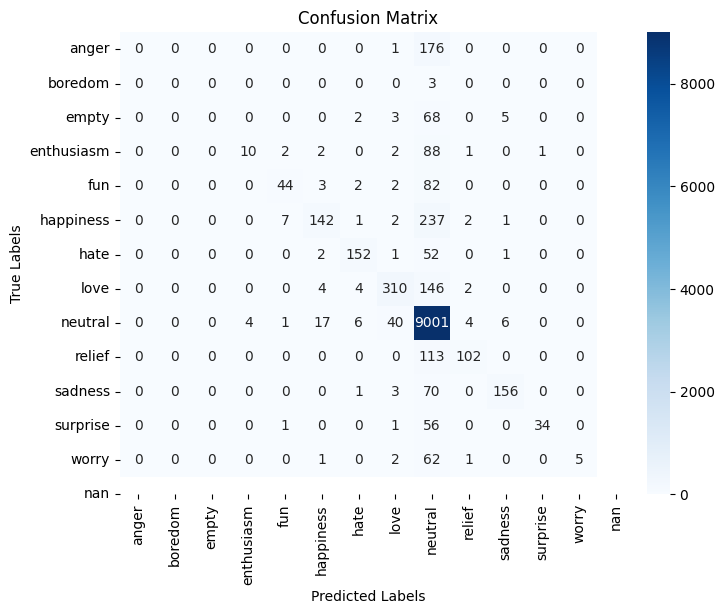

In [ ]:
cm=confusion_matrix(y_test_encoded,y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
#example test cases
test_cases=[
    "This is a happy message",
    "I am feeling very sad today",
    "What a frustrating experience!",
    "This is so exciting!"
]
for text in test_cases:
  #preprocess the text
  text=text.lower()
  text=word_tokenize(text)
  text=[word for word in text if word not in string.punctuation]
  text=[word for word in text if word not in stop_words]
  text=[stemmer.stem(word) for word in text]

  #vectorize the preprocessed text
  vectorized_text=vectorize_text(text)

  #If any word in found in the word2vec model,proceed with prediction
  if vectorized_text:
    #convert the list of word embeddings to a Numpy array
    vectorized_text_array=np.array(vectorized_text)

    #calculate the average embeddings for the text
    text_embedding=np.mean(vectorized_text_array,axis=0)

    #reshape the text embeddings to match the models input shape
    text_embedding=text_embedding.reshape(1,-1,1)

    #predict the emotion
    prediction=proposed_model.predict(text_embedding)
    predicted_label=label_encoder.classes_[np.argmax(prediction)]
    print(f"Text: {text}\nPredicted Emotion:{predicted_label}\n")
  else:
    print(f"Text: {text}\nNo words found in the word2vec model for this text.\n")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Text: ['happi', 'messag']
Predicted Emotion:neutral

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Text: ['feel', 'sad', 'today']
Predicted Emotion:sadness

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Text: ['frustrat', 'experi']
Predicted Emotion:neutral

Text: ['excit']
No words found in the word2vec model for this text.

